In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Data Injection


In [8]:
!wget -O household_power_consumption.txt https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip

--2026-10-15 11:24:53--  https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘household_power_consumption.txt’

household_power_con     [    <=>             ]  19.68M  30.8MB/s    in 0.6s    

2026-10-15 11:24:54 (30.8 MB/s) - ‘household_power_consumption.txt’ saved [20640916]



In [9]:
import zipfile
import os

with zipfile.ZipFile("household_power_consumption.txt", "r") as zip_ref:
    zip_ref.extractall("household_data")

print(os.listdir("household_data"))

['household_power_consumption.txt']


In [10]:
import glob

files = glob.glob("household_data/**/*.txt", recursive=True)
print(files)

['household_data/household_power_consumption.txt']


In [11]:
DATA_PATH=files[0]
df=pd.read_csv(DATA_PATH,sep=";",decimal=",",na_values=["?"]
               ,low_memory=False
               )
print("dataset loaded successfully")

dataset loaded successfully


In [12]:
print(df.head())
print("\nDimentions:",df.shape)
print("\ncolumn name:")
print(df.columns.tolist())

         Date      Time Global_active_power Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00               4.216                 0.418  234.840   
1  16/12/2006  17:25:00               5.360                 0.436  233.630   
2  16/12/2006  17:26:00               5.374                 0.498  233.290   
3  16/12/2006  17:27:00               5.388                 0.502  233.740   
4  16/12/2006  17:28:00               3.666                 0.528  235.680   

  Global_intensity Sub_metering_1 Sub_metering_2 Sub_metering_3  
0           18.400          0.000          1.000         17.000  
1           23.000          0.000          1.000         16.000  
2           23.000          0.000          2.000         17.000  
3           23.000          0.000          1.000         17.000  
4           15.800          0.000          1.000         17.000  

Dimentions: (2075259, 9)

column name:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity',

check missing values


In [13]:
print("missing value per columns")
print(df.isnull().sum())
print("total missing values")
print(df.isnull().sum().sum())
print("\n missing percentage")
print((df.isnull().sum().sum() / df.size) * 100)

missing value per columns
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64
total missing values
181853

 missing percentage
0.9736562467089115


In [14]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [15]:
display(df.describe())

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2075259,2075259,2049280,2049280,2049280,2049280,2049280,2049280,2049280
unique,1442,1440,4186,532,2837,221,88,81,32
top,25/11/2010,19:43:00,0.218,0.000,241.180,1.000,0.000,0.000,0.000
freq,1440,1442,9565,481561,3559,172785,1880175,1436830,852092


In [16]:
measurement_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

print("Rows where all measurements are missing:")
print(df[measurement_cols].isnull().all(axis=1).sum())

print("\nMissing values per column:")
print(df[measurement_cols].isnull().sum())

Rows where all measurements are missing:
25979

Missing values per column:
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [17]:
df = df.dropna(subset=measurement_cols, how="all")

print(df[measurement_cols].isnull().sum())
print("Total missing values:", df[measurement_cols].isnull().sum().sum())
print("New shape:", df.shape)

Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64
Total missing values: 0
New shape: (2049280, 9)


In [18]:
measurement_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

print("Minimum values:")
print(df[measurement_cols].min())
for col in measurement_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df[measurement_cols].dtypes)
print("\nNegative values per column:")
print((df[measurement_cols] < 0).sum())

Minimum values:
Global_active_power        0.076
Global_reactive_power      0.000
Voltage                  223.200
Global_intensity           0.200
Sub_metering_1             0.000
Sub_metering_2             0.000
Sub_metering_3             0.000
dtype: object
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

Negative values per column:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


In [19]:
df["Datetime"]=pd.to_datetime(df["Date"]+" "+df["Time"],format="%d/%m/%Y %H:%M:%S")
df=df.sort_values("Datetime").reset_index(drop=True)
df["time_diff"]=df["Datetime"].diff()
print(df["time_diff"].value_counts().head(10))


time_diff
0 days 00:01:00    2049208
0 days 00:02:00         38
0 days 00:03:00         14
0 days 00:04:00          2
2 days 14:04:00          1
0 days 00:34:00          1
0 days 01:24:00          1
0 days 00:48:00          1
0 days 00:22:00          1
0 days 00:44:00          1
Name: count, dtype: int64


In [20]:
expected_time = pd.date_range(
    start=df["Datetime"].min(),
    end=df["Datetime"].max(),
    freq="min"
)

actual_time = pd.DatetimeIndex(df["Datetime"])

missing_times = expected_time.difference(actual_time)

print("Expected timestamps:", len(expected_time))
print("Actual timestamps:", len(actual_time))
print("Missing timestamps:", len(missing_times))

Expected timestamps: 2075259
Actual timestamps: 2049280
Missing timestamps: 25979


In [21]:
missing_df = pd.DataFrame({"Datetime": missing_times})

missing_df = missing_df.sort_values("Datetime")

missing_df["gap_group"] = (
    missing_df["Datetime"].diff() != pd.Timedelta(minutes=1)
).cumsum()

gap_lengths = missing_df.groupby("gap_group").size()

print("Number of missing gaps:", len(gap_lengths))
print("\nLargest missing gaps (in minutes):")
print(gap_lengths.sort_values(ascending=False).head(10))

Number of missing gaps: 71

Largest missing gaps (in minutes):
gap_group
69    7226
70    5237
7     3723
50    3305
59    3129
63    2027
52     891
16      83
39      70
17      47
dtype: int64


In [22]:
# Set Datetime as the index
df = df.set_index("Datetime").sort_index()

# Count valid minute readings in each hour
hourly_count = df["Global_active_power"].resample("h").count()

# Check how many hours have all 60 readings
complete_hours = (hourly_count == 60).sum()
incomplete_hours = (hourly_count < 60).sum()

print("Complete hours:", complete_hours)
print("Incomplete hours:", incomplete_hours)
print("Total hours:", len(hourly_count))

Complete hours: 34085
Incomplete hours: 504
Total hours: 34589


In [23]:
# Calculate hourly energy consumption
hourly_energy = df["Global_active_power"].resample("h").sum() / 60

# Keep only hours with all 60 valid readings
hourly_energy = hourly_energy[hourly_count == 60]

print("Hourly dataset shape:", hourly_energy.shape)
print("\nFirst 5 hourly energy values:")
print(hourly_energy.head())

Hourly dataset shape: (34085,)

First 5 hourly energy values:
Datetime
2006-12-16 18:00:00    3.632200
2006-12-16 19:00:00    3.400233
2006-12-16 20:00:00    3.268567
2006-12-16 21:00:00    3.056467
2006-12-16 22:00:00    2.200133
Name: Global_active_power, dtype: float64


In [24]:
# Convert Series into a DataFrame
hourly_df = hourly_energy.to_frame(name="Hourly_Energy_kWh")

# Make Datetime a regular column
hourly_df = hourly_df.reset_index()

# Check the result
print(hourly_df.head())
print("\nDataset shape:", hourly_df.shape)
print("\nMissing values:")
print(hourly_df.isnull().sum())

             Datetime  Hourly_Energy_kWh
0 2006-12-16 18:00:00           3.632200
1 2006-12-16 19:00:00           3.400233
2 2006-12-16 20:00:00           3.268567
3 2006-12-16 21:00:00           3.056467
4 2006-12-16 22:00:00           2.200133

Dataset shape: (34085, 2)

Missing values:
Datetime             0
Hourly_Energy_kWh    0
dtype: int64


Visualization


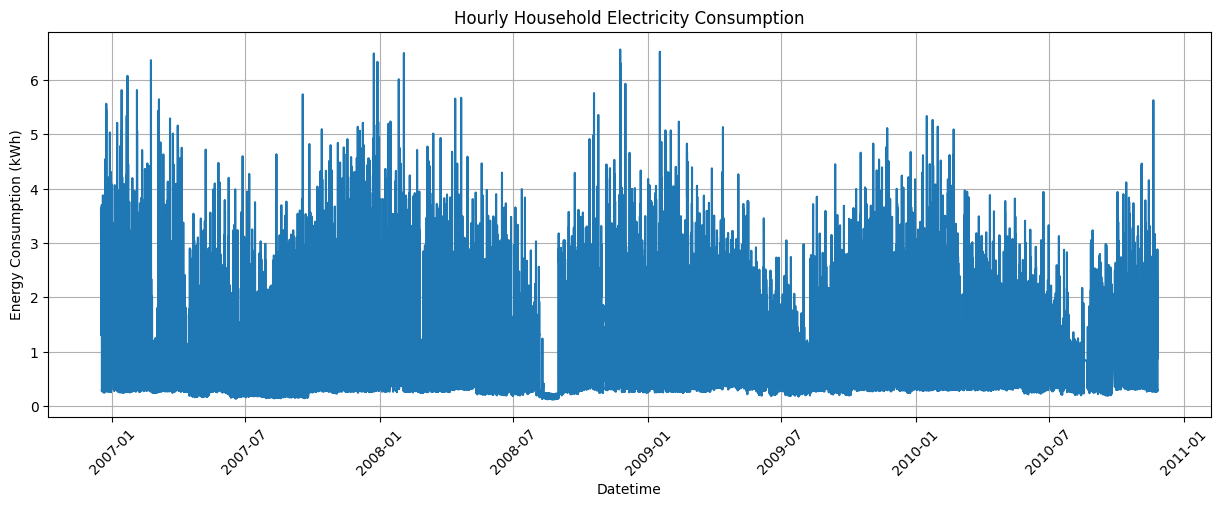

In [25]:
plt.figure(figsize=(15,5))
sns.lineplot(data=hourly_df,x="Datetime",y="Hourly_Energy_kWh")
plt.title("Hourly Household Electricity Consumption")
plt.xlabel("Datetime")
plt.ylabel("Energy Consumption (kWh)")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

HistPlot

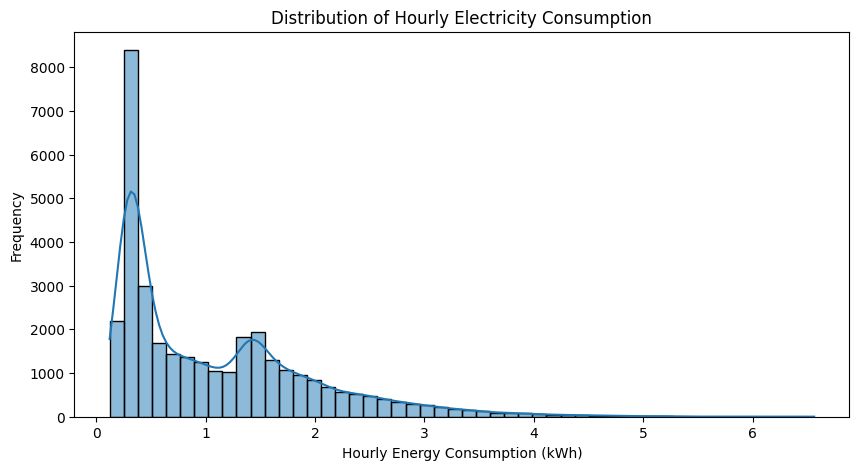

In [26]:
plt.figure(figsize=(10, 5))
sns.histplot(  data=hourly_df,
    x="Hourly_Energy_kWh",
    kde=True,
    bins=50)
plt.title("Distribution of Hourly Electricity Consumption")
plt.xlabel("Hourly Energy Consumption (kWh)")
plt.ylabel("Frequency")

plt.show()

In [27]:
hourly_df["Hourly_Energy_kWh"].describe()

,Hourly_Energy_kWh
count,34085.000000
mean,1.090361
std,0.896738
min,0.124000
25%,0.341700
50%,0.801833
75%,1.578133
max,6.560533


In [28]:
hourly_df["DayOfWeek"] = hourly_df["Datetime"].dt.dayofweek
hourly_df["Hour"]=hourly_df["Datetime"].dt.hour
hourly_df["Month"] = hourly_df["Datetime"].dt.month
print(hourly_df[["Datetime","Hour", "Month","DayOfWeek", "Hourly_Energy_kWh"]].head())

             Datetime  Hour  Month  DayOfWeek  Hourly_Energy_kWh
0 2006-12-16 18:00:00    18     12          5           3.632200
1 2006-12-16 19:00:00    19     12          5           3.400233
2 2006-12-16 20:00:00    20     12          5           3.268567
3 2006-12-16 21:00:00    21     12          5           3.056467
4 2006-12-16 22:00:00    22     12          5           2.200133


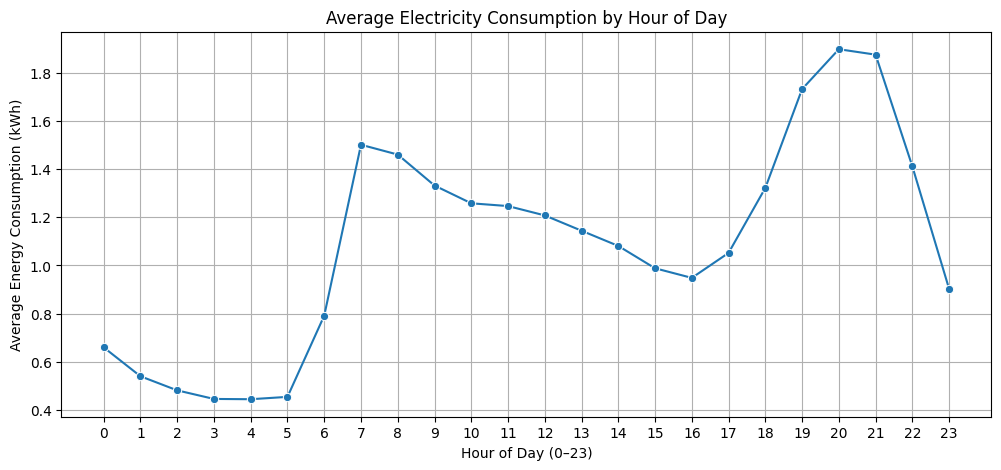

In [29]:
hourly_df["Hour"]=hourly_df["Datetime"].dt.hour
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_df,
    x="Hour",
    y="Hourly_Energy_kWh",
    estimator="mean",
    errorbar=None,
    marker="o"
)

plt.title("Average Electricity Consumption by Hour of Day")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Average Energy Consumption (kWh)")
plt.xticks(range(24))
plt.grid(True)
plt.show()

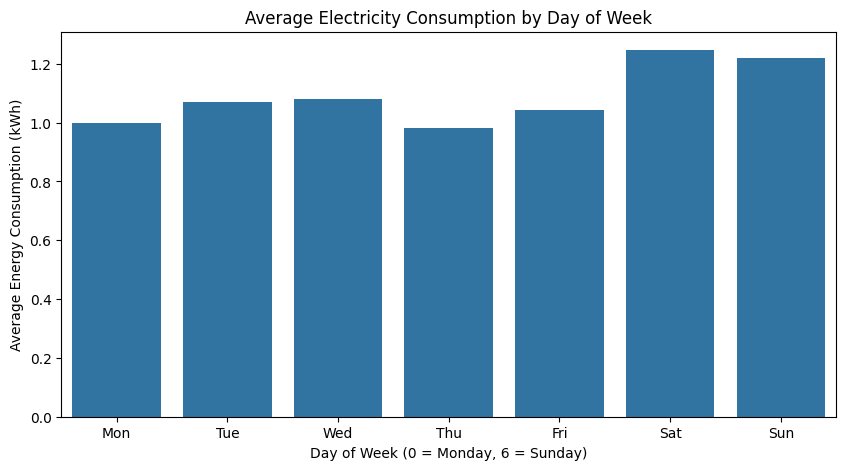

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

sns.barplot(
    data=hourly_df,
    x="DayOfWeek",
    y="Hourly_Energy_kWh",
    estimator="mean",
    errorbar=None
)

plt.title("Average Electricity Consumption by Day of Week")
plt.xlabel("Day of Week (0 = Monday, 6 = Sunday)")
plt.ylabel("Average Energy Consumption (kWh)")
plt.xticks(
    ticks=range(7),
    labels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)
plt.show()

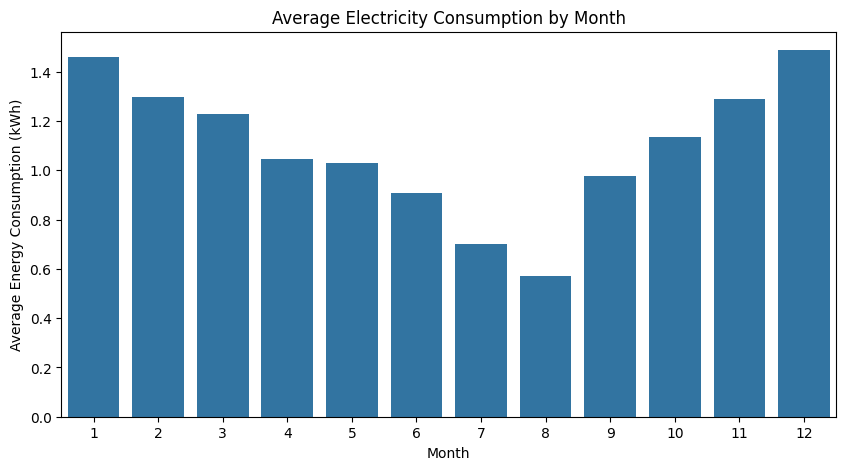

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

sns.barplot(
    data=hourly_df,
    x="Month",
    y="Hourly_Energy_kWh",
    estimator="mean",
    errorbar=None
)

plt.title("Average Electricity Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Energy Consumption (kWh)")
plt.xticks(range(12), range(1, 13))
plt.show()

<Axes: >

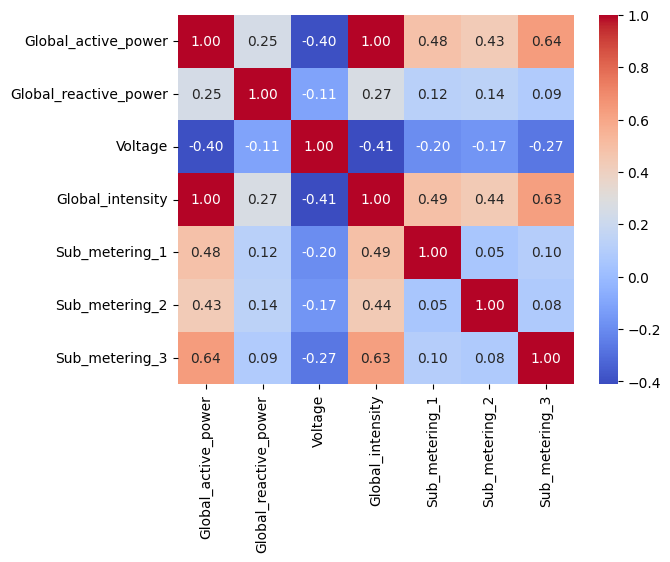

In [32]:
measurement_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

correlation_matrix = df[measurement_cols].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

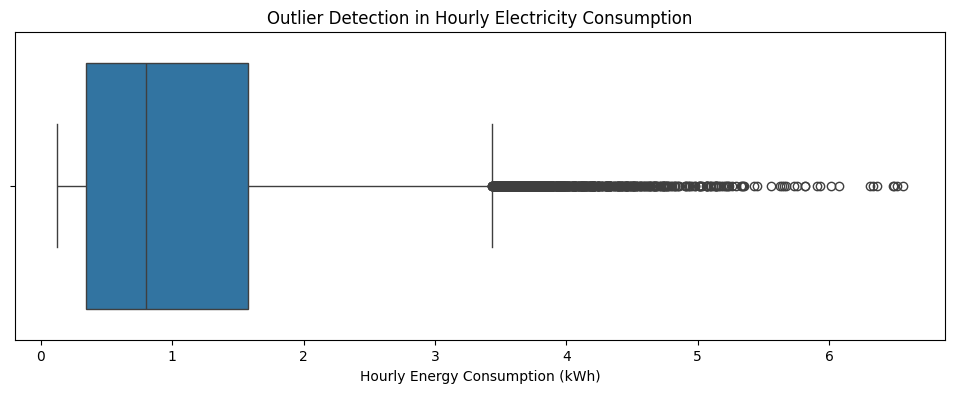

In [33]:

plt.figure(figsize=(12, 4))

sns.boxplot(
    x=hourly_df["Hourly_Energy_kWh"]
)

plt.title("Outlier Detection in Hourly Electricity Consumption")
plt.xlabel("Hourly Energy Consumption (kWh)")
plt.show()

In [34]:
Q1 = hourly_df["Hourly_Energy_kWh"].quantile(0.25)
Q3 = hourly_df["Hourly_Energy_kWh"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 0.3417
Q3: 1.5781333333333334
IQR: 1.2364333333333333
Lower limit: -1.51295
Upper limit: 3.432783333333333


In [35]:
outliers = hourly_df[
    (hourly_df["Hourly_Energy_kWh"] < lower_limit) |
    (hourly_df["Hourly_Energy_kWh"] > upper_limit)
]

print("Number of potential outliers:", len(outliers))

print(
    "Percentage of potential outliers:",
    round(len(outliers) / len(hourly_df) * 100, 2),
    "%"
)

Number of potential outliers: 728
Percentage of potential outliers: 2.14 %


data preparation


In [36]:
data = hourly_df[["Hourly_Energy_kWh"]].copy()
# 3. Check data quality
print("Dataset shape:", data.shape)
print("Missing values:", data.isnull().sum().sum())
print("Duplicate timestamps:", hourly_df["Datetime"].duplicated().sum())
print("Sorted chronologically:",
      hourly_df["Datetime"].is_monotonic_increasing)

# 4. Check gaps between consecutive observations
time_diff = hourly_df["Datetime"].diff()

print("Gaps longer than one hour:",
      (time_diff > pd.Timedelta(hours=1)).sum())
# Find gaps longer than one hour
time_diff = hourly_df["Datetime"].diff()

gap_info = hourly_df.loc[
    time_diff > pd.Timedelta(hours=1),
    ["Datetime"]
].copy()

gap_info["Gap_Duration"] = time_diff[
    time_diff > pd.Timedelta(hours=1)
].values

print("Number of gaps:", len(gap_info))
print(gap_info.head(10))

Dataset shape: (34085, 1)
Missing values: 0
Duplicate timestamps: 0
Sorted chronologically: True
Gaps longer than one hour: 68
Number of gaps: 68
                Datetime    Gap_Duration
113  2006-12-21 12:00:00 0 days 02:00:00
327  2006-12-30 11:00:00 0 days 02:00:00
694  2007-01-14 19:00:00 0 days 02:00:00
1028 2007-01-28 18:00:00 0 days 02:00:00
1632 2007-02-22 23:00:00 0 days 02:00:00
2370 2007-03-25 18:00:00 0 days 02:00:00
3168 2007-04-30 15:00:00 2 days 16:00:00
3940 2007-06-01 20:00:00 0 days 02:00:00
4061 2007-06-06 22:00:00 0 days 02:00:00
4122 2007-06-09 13:00:00 0 days 03:00:00


splitting data

In [37]:

n = len(hourly_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)


train_df = hourly_df.iloc[:train_end].copy()
val_df = hourly_df.iloc[train_end:val_end].copy()
test_df = hourly_df.iloc[val_end:].copy()



Robust from outliers

In [38]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

train_scaled = scaler.fit_transform(
    train_df[["Hourly_Energy_kWh"]]
)

val_scaled = scaler.transform(
    val_df[["Hourly_Energy_kWh"]]
)

test_scaled = scaler.transform(
    test_df[["Hourly_Energy_kWh"]]
)

print("Train:", train_scaled.shape)
print("Validation:", val_scaled.shape)
print("Test:", test_scaled.shape)

Train: (23859, 1)
Validation: (5113, 1)
Test: (5113, 1)


24-hour sequences for the LSTM

In [39]:
import numpy as np
import pandas as pd

LOOKBACK = 24

def create_sequences(scaled_values, datetimes):
    X, y = [], []

    values = scaled_values.flatten()
    times = pd.Series(pd.to_datetime(datetimes)).reset_index(drop=True)

    for i in range(LOOKBACK, len(values)):
        # Check the 24 input hours and the target hour
        window_times = times.iloc[i - LOOKBACK:i + 1]

        if (window_times.diff().dropna() == pd.Timedelta(hours=1)).all():
            X.append(values[i - LOOKBACK:i])
            y.append(values[i])

    return (
        np.array(X).reshape(-1, LOOKBACK, 1),
        np.array(y)
    )

X_train, y_train = create_sequences(
    train_scaled, train_df["Datetime"]
)

X_val, y_val = create_sequences(
    val_scaled, val_df["Datetime"]
)

X_test, y_test = create_sequences(
    test_scaled, test_df["Datetime"]
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (22679, 24, 1)
y_train: (22679,)
X_val: (4824, 24, 1)
y_val: (4824,)
X_test: (4921, 24, 1)
y_test: (4921,)


Model config

In [40]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
model=Sequential([
    LSTM(64,return_sequences=True,
         input_shape=(24,1)),
    Dropout(0.2),
    LSTM(32),
    Dense(16,activation="relu"),
    Dense(1)
])
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="mae")
        ,
        tf.keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

EarlyStopping

In [41]:
early_stopping=tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True

)

Train model

In [42]:
history=model.fit(
    X_train,y_train,validation_data=(X_val,y_val),
    epochs=30,batch_size=32,
    callbacks=[early_stopping],
    shuffle=False
)

Epoch 1/30
709/709 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - loss: 0.3285 - mae: 0.4184 - rmse: 0.5731 - val_loss: 0.2847 - val_mae: 0.3856 - val_rmse: 0.5336
Epoch 2/30
709/709 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - loss: 0.2470 - mae: 0.3485 - rmse: 0.4970 - val_loss: 0.2785 - val_mae: 0.3688 - val_rmse: 0.5277
Epoch 3/30
709/709 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - loss: 0.2340 - mae: 0.3339 - rmse: 0.4837 - val_loss: 0.2522 - val_mae: 0.3504 - val_rmse: 0.5022
Epoch 4/30
709/709 ━━━━━━━━━━━━━━━━━━━━ 20s 21ms/step - loss: 0.2287 - mae: 0.3285 - rmse: 0.4782 - val_loss: 0.2520 - val_mae: 0.3509 - val_rmse: 0.5020
Epoch 5/30
709/709 ━━━━━━━━━━━━━━━━━━━━ 15s 22ms/step - loss: 0.2272 - mae: 0.3272 - rmse: 0.4767 - val_loss: 0.2474 - val_mae: 0.3496 - val_rmse: 0.4974
Epoch 6/30
709/709 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - loss: 0.2251 - mae: 0.3251 - rmse: 0.4744 - val_loss: 0.2476 - val_mae: 0.3513 - val_rmse: 0.4976
Epoch 7/30
709/709 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - loss: 0.2243 - mae: 

In [43]:
from google.colab import drive
import os
# drive.mount('/content/drive')
save_dir = "/content/drive/MyDrive/Electricity_Forecasting"
os.makedirs(save_dir, exist_ok=True)

print("Folder created:", os.path.exists(save_dir))
model.save(os.path.join(save_dir, "electricity_lstm.keras"))
print("Model saved successfully!")

Folder created: True
Model saved successfully!


Load Save Model

In [44]:
# from tensorflow.keras.models import load_model
# import os
# from google.colab import drive
# # drive.mount('/content/drive')
# model_path = "/content/drive/MyDrive/Electricity_Forecasting/electricity_lstm.keras"

# model = load_model(model_path)

Evaluation

In [45]:
y_pred_scaled=model.predict(X_test)
print("Predictions shape:", y_pred_scaled.shape)
print("Actual values shape:", y_test.shape)


154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
Predictions shape: (4921, 1)
Actual values shape: (4921,)


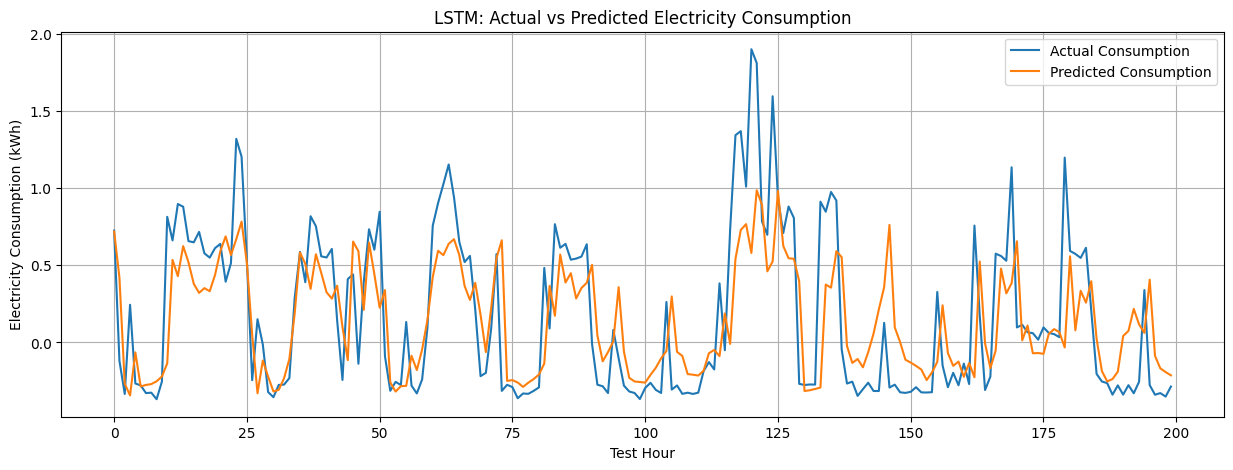

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(y_test[:200], label="Actual Consumption")
plt.plot(y_pred_scaled[:200], label="Predicted Consumption")

plt.title("LSTM: Actual vs Predicted Electricity Consumption")
plt.xlabel("Test Hour")
plt.ylabel("Electricity Consumption (kWh)")
plt.legend()
plt.grid(True)
plt.show()

In [47]:
print(f"Training loss:{history.history['loss'][-1]:.4f}")
print(f"validation loss:{history.history['val_loss'][-1]:.4f}")



Training loss:0.2089
validation loss:0.2350


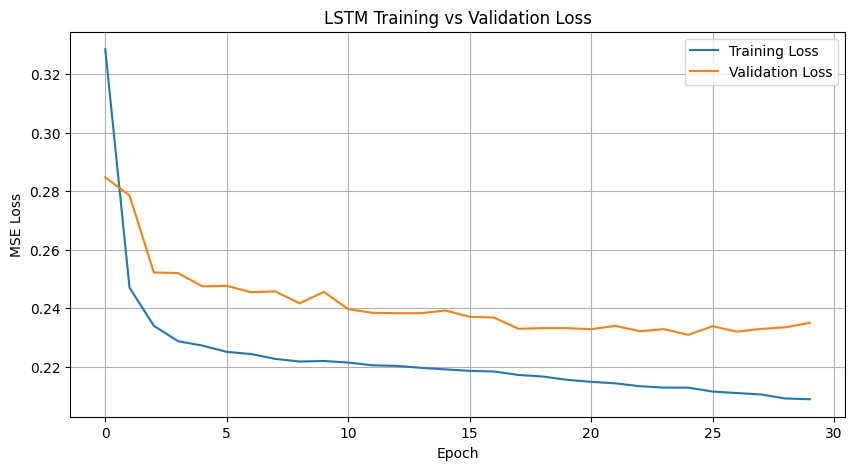

In [48]:

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("LSTM Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [49]:

test_loss = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", test_loss[0])

Test Loss: 0.15516149997711182


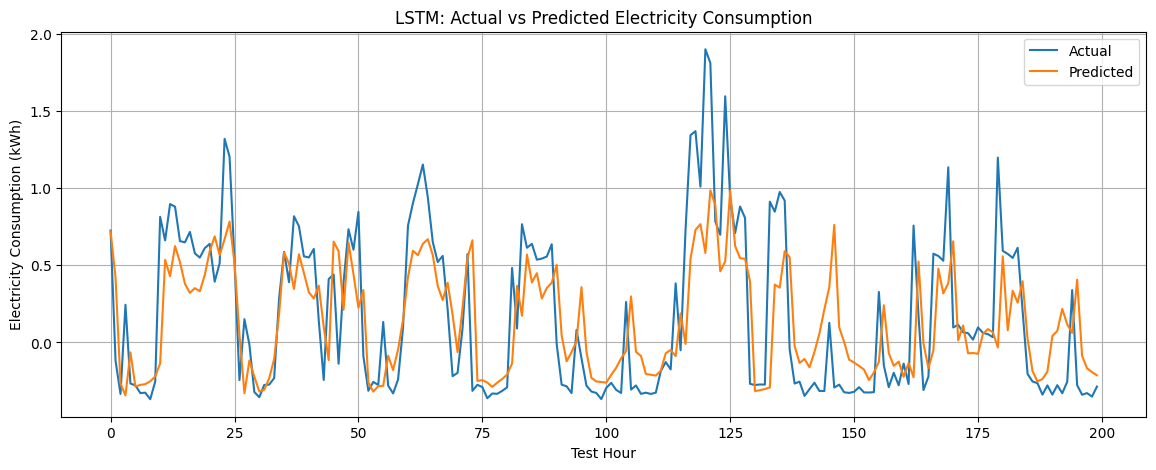

In [50]:
plot=pd.DataFrame({
    "Hours":range(200),
    "Actual":y_test.flatten()[:200],
    "Predicted":y_pred_scaled.flatten()[:200]
})
plt.figure(figsize=(14,5))
sns.lineplot(data=plot,x="Hours",y="Actual",label="Actual")
sns.lineplot(data=plot,x="Hours",y="Predicted",label="Predicted")
plt.title("LSTM: Actual vs Predicted Electricity Consumption")
plt.xlabel("Test Hour")
plt.ylabel("Electricity Consumption (kWh)")
plt.legend()
plt.grid(True)
plt.show()



METRICS

In [51]:
y_actual=scaler.inverse_transform(y_test.reshape(-1,1))
y_pred=scaler.inverse_transform(y_pred_scaled.reshape(-1,1))
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae, "kWh")
print("RMSE:", rmse, "kWh")
print("R² Score:", r2)

MAE: 0.34718936440674486 kWh
RMSE: 0.4933534183186567 kWh
R² Score: 0.5181919031392341


In [52]:
from sklearn.metrics import accuracy_score,confusion_matrix

threshold = train_df["Hourly_Energy_kWh"].quantile(0.75)
y_true_class = (y_actual.flatten() >= threshold).astype(int)
y_pred_class = (y_pred.flatten() >= threshold).astype(int)
accuracy = accuracy_score(y_true_class, y_pred_class)
print(" threshold:", threshold, "kWh")

print("Accuracy :", accuracy * 100)


 threshold: 1.5751333333333335 kWh
Accuracy : 85.18593781751676


<Axes: >

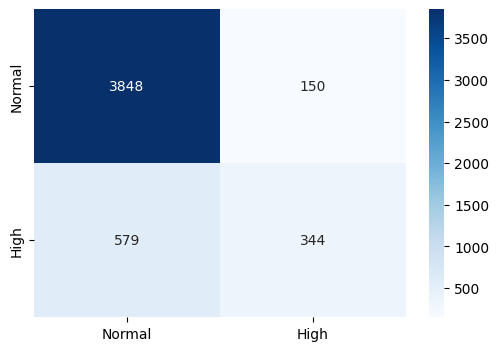

In [53]:
cm=confusion_matrix(y_true_class, y_pred_class)
plt.figure(figsize=(6, 4))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",
             xticklabels=["Normal", "High"],
    yticklabels=["Normal", "High"])

Prediction

In [63]:


n = int(input("How many hours ahead do you want to predict? "))

if n < 1:
    raise ValueError("Enter a number greater than or equal to 1.")


last_24_hrs = hourly_df["Hourly_Energy_kWh"].values[-24:]

# 3. Scale the readings using the saved scaler
last_24_scaled = scaler.transform(
    pd.DataFrame({
        "Hourly_Energy_kWh": last_24_hrs
    })
).flatten()


last_time = pd.to_datetime(hourly_df["Datetime"].iloc[-1])

predictions = []

# 5. Predict sequentially
for i in range(n):


    X_new = last_24_scaled[-24:].reshape(1, 24, 1)


    prediction_scaled = model.predict(X_new, verbose=0)


    prediction_kwh = float(
        scaler.inverse_transform(prediction_scaled)[0, 0]
    )

    forecast_time = last_time + pd.Timedelta(hours=i + 1)

    predictions.append({
        "Forecast Date": forecast_time.strftime("%Y-%m-%d"),
        "Forecast Time": forecast_time.strftime("%I:%M %p"),
        "Predicted Consumption (kWh)": round(prediction_kwh, 3)
    })


    last_24_scaled = np.append(
        last_24_scaled,
        prediction_scaled[0, 0]
    )

# 7. Display results
result_df = pd.DataFrame(predictions)

print(f"\nElectricity Forecast: Next {n} Hour(s)")
print("Last historical timestamp:", last_time)
display(result_df)

How many hours ahead do you want to predict? 2

Electricity Forecast: Next 2 Hour(s)
Last historical timestamp: 2010-11-26 20:00:00


,Forecast Date,Forecast Time,Predicted Consumption (kWh)
0,2010-11-26,09:00 PM,1.020
1,2010-11-26,10:00 PM,0.773
